<a href="https://colab.research.google.com/github/SarahAbuirmeileh/PyTorch_Learning/blob/03-PyTorch-Computer-Vision/notebooks/learning/03_PyTorch_Computer_Vision.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Computer Vision

**Computer vision** is the art of teaching a computer to see.

**Computer vision tasks** include methods for acquiring, processing, analyzing, and understanding digital images, and extraction of high-dimensional data from the real world in order to produce numerical or symbolic information, e.g. in the form of decisions



## 0. Computer Vision libraries in PyTorch

* `torchvision` - base domain library for pytorch computer vision
* `torchvision.datasets` - get datasets and data loading functions for computer vision
* `torchvision.models` - get pre-trained computer vision models that you can legerage for your own problems
* `torchvision.transforms` - funs for manupulating your vision data (images) to be suitable for use with ML models
* `torch.utils.data.Dataset` - Base dataset class for PyTorch  
* `torch.utils.data.Dataloader` - Create a python iterable over a dataset



In [1]:
# import libraries

import torch
import torchvision
from torchvision import datasets
from torchvision import transforms
from torchvision.transforms import ToTensor

# for visulaization
import matplotlib.pyplot as plt

# 1. Getting our dataset

We are goig to use `fashionMNIST` from `torchvision.Datasets`

In [2]:
# Seting up traning data

train_data = datasets.FashionMNIST(
    root="data", # Where to download data to
    train=True, # Do you  want a traning dataset
    download=True,
    transform=ToTensor(), # How do we want to transform the data-> torchvision.transforms.ToTensor()
    target_transform=None # How do we want to transform the lables/targets
)

# Setting up test data

test_data = datasets.FashionMNIST(
    root="data",
    train=False,
    download=True,
    transform=ToTensor(),
    target_transform=None
)

In [3]:
len(train_data), len(test_data)

(60000, 10000)

In [4]:
# See the first training example

image, label = train_data[0]
image, label

(tensor([[[0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000,
           0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000,
           0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000,
           0.0000, 0.0000, 0.0000, 0.0000],
          [0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000,
           0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000,
           0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000,
           0.0000, 0.0000, 0.0000, 0.0000],
          [0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000,
           0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000,
           0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000,
           0.0000, 0.0000, 0.0000, 0.0000],
          [0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000,
           0.0000, 0.0000, 0.0000, 0.0000, 0.0039, 0.0000, 0.0000, 0.0510,
           0.2863, 0.0000, 0.0000, 0.0039, 

In [5]:
class_names = train_data.classes
class_names

['T-shirt/top',
 'Trouser',
 'Pullover',
 'Dress',
 'Coat',
 'Sandal',
 'Shirt',
 'Sneaker',
 'Bag',
 'Ankle boot']

In [6]:
class_to_idx =  train_data.class_to_idx
class_to_idx

{'T-shirt/top': 0,
 'Trouser': 1,
 'Pullover': 2,
 'Dress': 3,
 'Coat': 4,
 'Sandal': 5,
 'Shirt': 6,
 'Sneaker': 7,
 'Bag': 8,
 'Ankle boot': 9}

In [86]:
image.shape, label.shape

AttributeError: 'int' object has no attribute 'shape'

In [8]:
type(image), type(label)

(torch.Tensor, int)

In [9]:
image.shape, label

(torch.Size([1, 28, 28]), 9)

In [10]:

# Check the shape of our image
print(f"Image shape: {image.shape} -> [color_channels, height, width]")
print(f"Image label: {class_names[label]}")

Image shape: torch.Size([1, 28, 28]) -> [color_channels, height, width]
Image label: Ankle boot


In [11]:
# c=1 -> one color channel (black & White)

In [12]:
# Visualize our data

import matplotlib.pyplot as plt
image, label = train_data[0]
print(f"Image shape: {image.shape}")

Image shape: torch.Size([1, 28, 28])


TypeError: Invalid shape (1, 28, 28) for image data

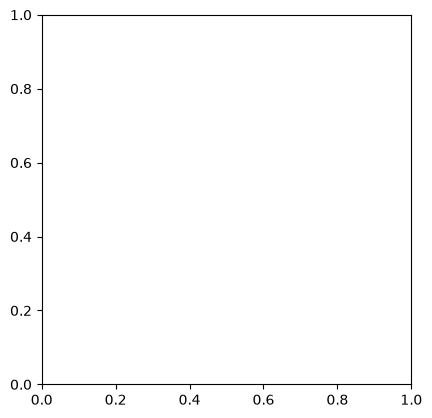

In [87]:
# visualizae the image

plt.imshow(image)

Text(0.5, 1.0, '9:Ankle boot')

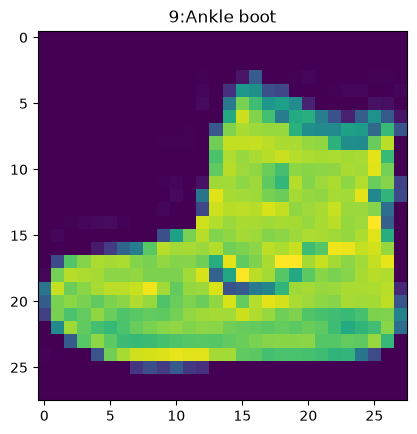

In [14]:
# plt expext (h, w, c) or without the color channel
# so we will squeeze the extra dimention

plt.imshow(image.squeeze())
# add a title to it
plt.title(f"{label}:{class_names[label]}")


(np.float64(-0.5), np.float64(27.5), np.float64(27.5), np.float64(-0.5))

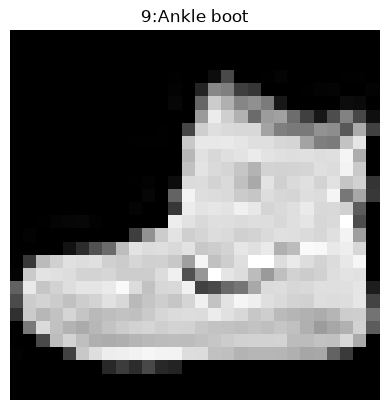

In [15]:
# pritn it gray
plt.imshow(image.squeeze(), cmap="gray")
plt.title(f"{label}:{class_names[label]}")
plt.axis(False)

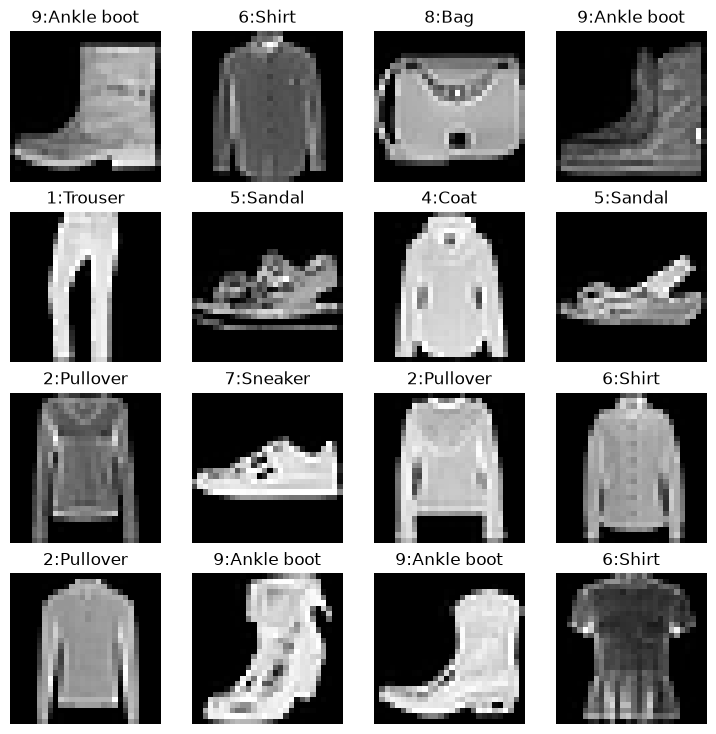

In [16]:
# plot more images

RANDOM_SEED=42

torch.manual_seed(RANDOM_SEED)
fig = plt.figure(figsize=(9, 9))
rows, cols = 4, 4 # print 16 image
for i in range(1, rows*cols +1):
  # choose random 16 image
  # size = to define the size of the output tensor
  # .item to get the value of the tensor
  random_idx = torch.randint(0, len(train_data), size=[1]).item()
  # print(random_idx)
  image, label = train_data[random_idx]
  fig.add_subplot(rows, cols, i)
  plt.imshow(image.squeeze(), cmap="gray")
  plt.title(f"{label}:{class_names[label]}")
  plt.axis(False)

### Do these data need linear lines or non-lieanrity ?

In [17]:
train_data, test_data

(Dataset FashionMNIST
     Number of datapoints: 60000
     Root location: data
     Split: Train
     StandardTransform
 Transform: ToTensor(),
 Dataset FashionMNIST
     Number of datapoints: 10000
     Root location: data
     Split: Test
     StandardTransform
 Transform: ToTensor())

## 2. Prepare our dataLoader

right now our data is in the form of pytorch dataset

`DataLoader` turn our dataset into a python iterable

more specifically, we want to turn our data into batches (or mini-batches)

** why we would to do this?**
1. it's more computaitoinlly efficint, as the computer hardware may not be able to look (store memory) at 60000 images at one hit.

So we break it down for 32 images at a time (batch size of 32)

2. It gives our nn more chances to update its greident per epoch

`if not batched` -> we have to look at 60,000 images per epoch -> get one update per epoch

`with batching` -> the nn update it's weight each 32 images

For more on mini-batches, see here: https://youtu.be/l4lSUAcvHFs

In [18]:
from torch.utils.data import DataLoader

BATCH_SIZE = 32

# Turn dataset into iterables (batches)

# shuffel to mix the data -> we might have the t-shirts ordered, we want to shake, them as we want the nn to learn the patter not the order of items

# -> to reduce model overfitting

train_dataloader = DataLoader(
  dataset=train_data,
  batch_size=BATCH_SIZE,
  shuffle=True
)

test_dataloader = DataLoader(
  dataset=test_data,
  batch_size=BATCH_SIZE,
  shuffle=False # No need to shuffle test data; we're only evaluating the model
)

train_dataloader, test_dataloader

(<torch.utils.data.dataloader.DataLoader at 0x7c571491a270>,
 <torch.utils.data.dataloader.DataLoader at 0x7c56ec479310>)

In [19]:
# Check out what we've created

print(f"Dataloaders: {train_dataloader, test_dataloader}")
print(f"length of the train dataloader: {len(train_dataloader)} batches of {BATCH_SIZE}")
print(f"length of the test dataloader: {len(test_dataloader)} batches of {BATCH_SIZE}")


Dataloaders: (<torch.utils.data.dataloader.DataLoader object at 0x7c571491a270>, <torch.utils.data.dataloader.DataLoader object at 0x7c56ec479310>)
length of the train dataloader: 1875 batches of 32
length of the test dataloader: 313 batches of 32


In [20]:
# Check out what's inside the traning dataloader

# iter -> transform the dataloader into a python iteratorable -> so we can loop through it
# next -> fitches the first item of that iterable

train_features_batch, train_labels_batch = next(iter(train_dataloader))
train_features_batch.shape, train_labels_batch.shape

(torch.Size([32, 1, 28, 28]), torch.Size([32]))

image size: torch.Size([1, 28, 28])
label: 6, label size: torch.Size([])


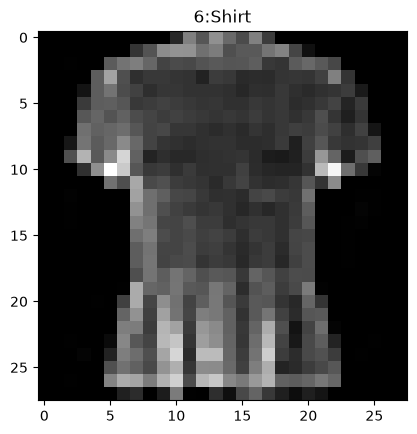

In [21]:
# show a random sample of a patch

torch.manual_seed(RANDOM_SEED)
random_idx = torch.randint(0, len(train_features_batch), size=[1]).item()

img, label = train_features_batch[random_idx], train_labels_batch[random_idx]

plt.imshow(image.squeeze(), cmap="gray")
# print(f"label:{label}")
plt.title(f"{label}:{class_names[label]}")

print(f"image size: {img.shape}")
print(f"label: {label}, label size: {label.shape}")

## 3. Build a baseline model

When starting to build a series of machine learning modelling experiments, it's best practice to start with a baseline model

**A baseline model** is a simple model you will try and improve upon  with subsequesnt modela/experiments

`Start simple then add compleixity when necessery

In [22]:
# Create a flatter layer
import torch.nn as nn
flatten_layer = nn.Flatten()

# Get a single sample
x = train_features_batch[0]
# y = train_labels_batch[0]
x.shape, x

# Flatten the sample
output = flatten_layer(x) # perform forward pass
# output.shape, output

print(f"Shape before flattening: {x.shape} -> [color_channels, height, width]")
print(f"Shape after flattening: {output.shape} ->[color_channels, height*width]")

# Why?
# B. we are trying to convert our data into vector sapce (n-dim)

Shape before flattening: torch.Size([1, 28, 28]) -> [color_channels, height, width]
Shape after flattening: torch.Size([1, 784]) ->[color_channels, height*width]


In [23]:
class FashionMNISTModelV0(nn.Module):
  def __init__(self, input_shape:int, hidden_units:int, output_shape:int ):
    super().__init__()
    self.layer_stack = nn.Sequential(
        nn.Flatten(),
        nn.Linear(in_features=input_shape, out_features=hidden_units),
        nn.Linear(in_features=hidden_units, out_features=output_shape),

    )

  def forward(self, x):
    return self.layer_stack(x)

In [24]:
[color_channels, height, width] = image.shape
color_channels, height, width

(1, 28, 28)

In [25]:
torch.manual_seed(RANDOM_SEED)
model_0 = FashionMNISTModelV0(
    input_shape=height*width,
    hidden_units=10,
    output_shape=len(class_names)
).to("cpu")
model_0

FashionMNISTModelV0(
  (layer_stack): Sequential(
    (0): Flatten(start_dim=1, end_dim=-1)
    (1): Linear(in_features=784, out_features=10, bias=True)
    (2): Linear(in_features=10, out_features=10, bias=True)
  )
)

In [26]:
# dummy input x to test our model
dummy_x=torch.rand([1, 1, 28, 28])
model_0(dummy_x).shape # 10-> the number of output classes

torch.Size([1, 10])

In [27]:
model_0.state_dict()

OrderedDict([('layer_stack.1.weight',
              tensor([[ 0.0273,  0.0296, -0.0084,  ..., -0.0142,  0.0093,  0.0135],
                      [-0.0188, -0.0354,  0.0187,  ..., -0.0106, -0.0001,  0.0115],
                      [-0.0008,  0.0017,  0.0045,  ..., -0.0127, -0.0188,  0.0059],
                      ...,
                      [-0.0116,  0.0273, -0.0344,  ...,  0.0176,  0.0283, -0.0011],
                      [-0.0230,  0.0257,  0.0291,  ..., -0.0187, -0.0087,  0.0001],
                      [ 0.0176, -0.0147,  0.0053,  ..., -0.0336, -0.0221,  0.0205]])),
             ('layer_stack.1.bias',
              tensor([-0.0093,  0.0283, -0.0033,  0.0255,  0.0017,  0.0037, -0.0302, -0.0123,
                       0.0018,  0.0163])),
             ('layer_stack.2.weight',
              tensor([[ 0.0614, -0.0687,  0.0021,  0.2718,  0.2109,  0.1079, -0.2279, -0.1063,
                        0.2019,  0.2847],
                      [-0.1495,  0.1344, -0.0740,  0.2006, -0.0475, -0.2514, -0.

### 3.1 Set up loss fun, optmizer and evlauation matric

1. `loss fun` -> CrossEntropyLoss -> b. we have multi-class classification
2. `optimizer` -> SGD -> as stohastice greaident descnt
3. `Evaluation Metric` -> since we are wotking with calssification probelm -> `accuracy`

** Accuracy we have 3 options: **
1. Write the code ourself -> it's easy as shown bellow
2. download from helper fun. file
3. **Use the built-in function in torchmetrics**

**1.**
```
# Calculate accuracy (a classification metric)
def accuracy_fn(y_true, y_pred):

    correct = torch.eq(y_true, y_pred).sum().item()
    # torch.eq() calculates where two tensors are equal
    
    acc = (correct / len(y_pred)) * 100

    return acc

```

**2.**
```
import requests
from pathlib import Path

# Download helper functions from Learn PyTorch repo (if not already downloaded)

if Path("helper_functions.py").is_file():
  print("helper_functions.py already exists, skipping download")
else:
  print("Downloading helper_functions.py")
  # Note: you need the "raw" GitHub URL for this to work
  request = requests.get("https://raw.githubusercontent.com/mrdbourke/pytorch-deep-learning/main/helper_functions.py")
  with open("helper_functions.py", "wb") as f:
    f.write(request.content)
```

In [28]:
# 3. use from torchmetrics
! pip install torchmetrics

In [29]:
from torchmetrics import Accuracy

accuracy_fn = Accuracy(task="multiclass", num_classes=len(class_names))

/usr/local/lib/python3.13/dist-packages/pandas/core/arrays/masked.py:63: UserWarning: Pandas requires version '1.5.0' or newer of 'bottleneck' (version '1.4.2' currently installed).
  from pandas.core import (


In [30]:
# set up loss fin and optimizer
import torch.optim as optim

loss_fn = nn.CrossEntropyLoss()
optimizer = optim.SGD(model_0.parameters(),
                      lr = 0.1)

### 3.2 create a function to time our experiminets

ML is very expirimental

Two things you'll often want to track are:
1. Model's performance **(loss & accuracy)**
2. How fast it runs

In [31]:
from timeit import default_timer as timer

def print_train_time(start:float,
                     end: float,
                     device:torch.device = None):
  total_time = end - start
  print(f"Train time on {device}: {total_time:.3f} seconds")
  return total_time

In [32]:
# example usage

start = timer()
# Some code ...
end = timer()
print_train_time(start, end, device="cpu")

Train time on cpu: 0.000 seconds


6.224600019777426e-05

### 3.3 train the model on batches of data

The optimizer will update model's parameter once per patch not per epoch

### 3.3 create a training loop and train the model on patches of data

1. loop through epochs
2. loop through traning batches, perform training steps, calc train **loss per batch**
3. loop through testing batches, perform testing steps, calc **test loss per batch**
4. print put what is happening.
5. Time it all   

In [33]:
# import tqdm for progress bar
from tqdm.auto import tqdm

# Set the seed and start the timer
torch.manual_seed(RANDOM_SEED)
train_time_start_on_cpu = timer()

# Set epochs (small for faster computations)
epochs = 3

# create traning and testing loops
for epoch in tqdm(range(epochs)):
  print(f"Epoch: {epoch} \n-----")

  # training
  train_loss = 0 # to accumalete loss per batch

  # add a loop to loop through our training batches
  # After each batch our model is getting slightly better
  for batch, (X, y) in enumerate(train_dataloader):
    # why we add enamurate?
    # to
    model_0.train()

    # 1. forward pass
    y_preds = model_0(X)

    # 2. clac the loss (per batch)
    loss = loss_fn(y_preds, y)
    train_loss += loss # cculamete it for every batch

    # 3. optimizer zero grad
    optimizer.zero_grad()

    # 4. loss backward
    loss.backward()

    # 5. optimizer step
    optimizer.step()

    if batch % 400 == 0:
      print(f"Looked at {batch * len(X)}/{len(train_dataloader.dataset)} samples.")

    # divide total train loss by the length of the train dataloader
    train_loss /= len(train_dataloader)

  ## Testing loop
  test_loss, test_acc = 0, 0
  model_0.eval()
  with torch.inference_mode():
    for X_test, y_test in test_dataloader:
      # 1. forward pass
      test_preds = model_0(X_test)

      # 2, calc the loss accumulativly
      test_loss += loss_fn(test_preds, y_test)

      # 3. calc the accuracy
      # .argmax(dim=1) -> to get the heighest problabitliy
      test_acc += accuracy_fn(y_test, test_preds.argmax(dim=1))

    # calc the test loss & acc avg / batch
    test_loss /= len(test_dataloader)
    test_acc /= len(test_dataloader)

  print(f"\nTrain loss: {train_loss:.4f} | Test loss: {test_loss:.4f}, Test acc: {test_acc:.4f}")

train_time_end_on_cpu = timer()
total_train_time_model_0 = print_train_time(start=train_time_start_on_cpu,
                                            end=train_time_end_on_cpu,
                                            device=str(next(model_0.parameters()).device))

  0%|          | 0/3 [00:00<?, ?it/s]

Epoch: 0 
-----
Looked at 0/60000 samples.
Looked at 12800/60000 samples.
Looked at 25600/60000 samples.
Looked at 38400/60000 samples.
Looked at 51200/60000 samples.

Train loss: 0.0002 | Test loss: 0.5095, Test acc: 0.8204
Epoch: 1 
-----
Looked at 0/60000 samples.
Looked at 12800/60000 samples.
Looked at 25600/60000 samples.
Looked at 38400/60000 samples.
Looked at 51200/60000 samples.

Train loss: 0.0003 | Test loss: 0.4799, Test acc: 0.8320
Epoch: 2 
-----
Looked at 0/60000 samples.
Looked at 12800/60000 samples.
Looked at 25600/60000 samples.
Looked at 38400/60000 samples.
Looked at 51200/60000 samples.

Train loss: 0.0002 | Test loss: 0.4766, Test acc: 0.8343
Train time on cpu: 32.758 seconds


In [34]:
# 4. Make a prediction and get Model 0 results

torch.manual_seed(RANDOM_SEED)
def eval_model(model: torch.nn.Module,
               data_loader:torch.utils.data.DataLoader,
               loss_fn:nn.Module,
               accuracy_fn):
  """Returns a dictionary containing the results of model predicting on data_loader."""

  loss, acc  = 0,0
  model.eval()
  with torch.inference_mode():
    # loop through the data loader
    for X, y in data_loader:
      # make a prediction with the model
      y_preds = model_0(X)

      # accumelate the loss and acc per batch
      loss += loss_fn(y_preds, y)
      acc += accuracy_fn(y_preds.argmax(dim=1), y)

    # scale the loss and acc to find the avg loss/acc per batch
    loss /= len(data_loader)
    acc /= len(data_loader)

  return {"model_name": model.__class__.__name__, # only works when model was created with a class
          "model_loss": loss.item(),
          "model_acc": acc}


# Calculate model 0 results on test dataset
model_0_results = eval_model(model=model_0,
                             data_loader=test_dataloader,
                             loss_fn=loss_fn,
                             accuracy_fn=accuracy_fn)
model_0_results


{'model_name': 'FashionMNISTModelV0',
 'model_loss': 0.47663894295692444,
 'model_acc': tensor(0.8343)}

### 5. Setup device agnostic-code (for using a GPU if there is one)

In [35]:
device = 'cuda' if torch.cuda.is_available() else "cpu"

device

'cpu'

## 6. Build a better model with non-linearity



In [36]:
# Create a model with linear and non-linear layers

class FashionMNISTModelV1(nn.Module):
  def __init__(self, input_shape:int, hidden_units:int, output_shape:int ):
    super().__init__()
    self.layer_stack = nn.Sequential(
        nn.Flatten(),
        nn.Linear(in_features=input_shape, out_features=hidden_units),
        nn.ReLU(),
        nn.Linear(in_features=hidden_units, out_features=output_shape),
        nn.ReLU()
    )

  def forward(self, x):
    return self.layer_stack(x)

In [37]:
# Create an instance of model 1
torch.manual_seed(RANDOM_SEED)
model_1 = FashionMNISTModelV1(input_shape=height*width, # this is the output of the flatten after our 28*28 image goes in
                              hidden_units=10,
                              output_shape=len(class_names)).to(device)


In [38]:
print(model_1.parameters())
# .parameters(): is a stram (data structer), we can not access the first elment by [0], so we use next() to get the first element
print(next(model_1.parameters()))

# Then we send it to he device
print(next(model_1.parameters()).device)

<generator object Module.parameters at 0x7c56ec4bc9e0>
Parameter containing:
tensor([[ 0.0273,  0.0296, -0.0084,  ..., -0.0142,  0.0093,  0.0135],
        [-0.0188, -0.0354,  0.0187,  ..., -0.0106, -0.0001,  0.0115],
        [-0.0008,  0.0017,  0.0045,  ..., -0.0127, -0.0188,  0.0059],
        ...,
        [-0.0116,  0.0273, -0.0344,  ...,  0.0176,  0.0283, -0.0011],
        [-0.0230,  0.0257,  0.0291,  ..., -0.0187, -0.0087,  0.0001],
        [ 0.0176, -0.0147,  0.0053,  ..., -0.0336, -0.0221,  0.0205]],
       requires_grad=True)
cpu


### 6.1 create a loss fun and optimizer

In [39]:
loss_fn = nn.CrossEntropyLoss()
optimizer = optim.SGD(model_1.parameters(),
                      lr=0.1)

device='cuda' if torch.cuda.is_available() else "cpu"

accuracy_fn = Accuracy(task="multiclass", num_classes=len(class_names)).to(device)

### 6.2 Functionzing traning and evaluation/testing loops  

Let's create a function for:

training loop - `train_step()`

testing loop - `test_step()`

In [40]:
def train_step(model:nn.Module,
               dataloader:torch.utils.data.DataLoader,
               loss_fn: nn.Module,
               optimizer:torch.optim.Optimizer,
               accuracy_fn,
               device:torch.device = device):

  # Put the model into training mode
  model.train()

  train_loss, train_accuracy = 0, 0

  # Loop through training batches
  for batch, (X, y) in enumerate(dataloader):
    X, y = X.to(device), y.to(device)

    # 1. Forward pass
    y_preds = model(X)

    # 2. Calculate the loss & acc (per batch)
    loss = loss_fn(y_preds, y)
    train_loss += loss
    train_accuracy += accuracy_fn(y_preds.argmax(dim=1), y) # logits -> prediction labels

    # 3. Optimizer zero grad
    optimizer.zero_grad()

    # 4. Loss backward
    loss.backward()

    # 5. Optimizer step
    optimizer.step()

  # Divide total train loss & acc by the length of the train dataloader (AFTER the loop)
  train_loss /= len(dataloader)
  train_accuracy /= len(dataloader)

  print(f"\nTrain loss: {train_loss:.4f} | Train CC: {train_accuracy:.4f}")

In [41]:
def test_step(model:nn.Module,
               dataloader:torch.utils.data.DataLoader,
               loss_fn: nn.Module,
               optimizer:torch.optim.Optimizer,
               accuracy_fn,
               device:torch.device = device):

  model.eval()
  test_loss, test_acc = 0, 0

  with torch.inference_mode():
    for X, y in test_dataloader:

      X, y = X.to(device), y.to(device)

      # 1. forward pass
      test_preds = model(X)

      # 2, calc the loss/acc accumulativly
      test_loss += loss_fn(test_preds, y_test)
      test_acc += accuracy_fn(y_test, test_preds.argmax(dim=1))

    # Adjust matric and print out

    # calc the test loss & acc avg / batch
    test_loss /= len(test_dataloader)
    test_acc /= len(test_dataloader)

    print(f"Test loss: {test_loss:.5f} | Test acc: {test_acc:.2f}%\n")

In [42]:
torch.manual_seed(RANDOM_SEED)

# Redefining the corrected test_step to fix the y_test batch size error
def test_step(model: nn.Module,
              dataloader: torch.utils.data.DataLoader,
              loss_fn: nn.Module,
              accuracy_fn,
              optimizer: torch.optim.Optimizer = None,  # optimizer is not needed in test but kept for signature compatibility
              device: torch.device = device):
  model.eval()
  test_loss, test_acc = 0, 0
  with torch.inference_mode():
    for X, y in dataloader:
      X, y = X.to(device), y.to(device)
      test_preds = model(X)
      test_loss += loss_fn(test_preds, y) # Fixed: using 'y' instead of 'y_test'
      test_acc += accuracy_fn(test_preds.argmax(dim=1), y) # Fixed: using 'y' instead of 'y_test' and aligned arguments

    test_loss /= len(dataloader)
    test_acc /= len(dataloader)
    print(f"Test loss: {test_loss:.5f} | Test acc: {test_acc:.2f}%\n")

# Measure the time
from timeit import default_timer as timer
train_time_start_on_gpu = timer()

epochs = 3

# Create a training and evaluation loop using train_step(), test_step()
for epoch in tqdm(range(epochs)):
  print(f"Epoch: {epoch} \n-----")
  train_step(model=model_1,
             dataloader=train_dataloader,
             loss_fn=loss_fn,
             accuracy_fn=accuracy_fn,
             optimizer=optimizer,
             device=device)
  test_step(model=model_1,
            dataloader=test_dataloader,
            loss_fn=loss_fn,
            accuracy_fn=accuracy_fn,
            optimizer=optimizer,
            device=device)

end_train_time_end_on_gpu = timer()

total_train_time_gpu = print_train_time(start=train_time_start_on_gpu,
                                        end=end_train_time_end_on_gpu,
                                        device=device)

  0%|          | 0/3 [00:00<?, ?it/s]

Epoch: 0 
-----

Train loss: 1.0920 | Train CC: 0.6134
Test loss: 0.95636 | Test acc: 0.65%

Epoch: 1 
-----

Train loss: 0.7810 | Train CC: 0.7193
Test loss: 0.72227 | Test acc: 0.74%

Epoch: 2 
-----

Train loss: 0.6703 | Train CC: 0.7594
Test loss: 0.68500 | Test acc: 0.75%

Train time on cpu: 44.173 seconds


In [43]:
!nvidia-smi

/bin/bash: line 1: nvidia-smi: command not found



> **Note:** : sometimes, depending on your data/hardware you might find that your model training is faster on CPU rather than GPU
>
> Why is this?
>
> 1. It could be that the overhead for copying data/model to and from the GPU outweighs the compute benefits offered by the GPU.
> 2. The hardware you're using has a better CPU in terms compute capability than the GPU.
> 3. For more on how to make your models compute faster, see here: https://horace.io/brrr_intro.html




In [44]:
# Get model 1 resutls dictitinary

model_1_results = eval_model(model=model_1,
                             data_loader=test_dataloader,
                             loss_fn=loss_fn,
                             accuracy_fn=accuracy_fn)

model_1_results

{'model_name': 'FashionMNISTModelV1',
 'model_loss': 0.47663894295692444,
 'model_acc': tensor(0.8343)}

In [45]:
model_0_results

{'model_name': 'FashionMNISTModelV0',
 'model_loss': 0.47663894295692444,
 'model_acc': tensor(0.8343)}

## Model 2: build a Convenutioanl Neural Network (CNN)

* Are also known as `ConvNtets`
* Knonw for thier capablities in finding patters in visual data.

**See** -> https://poloclub.github.io/cnn-explainer/


In [46]:
from torch.nn.modules.pooling import MaxPool2d
from torch.nn.modules.activation import ReLU
# Create a CNN

class FashionMNISTModelV2(nn.Module):
  """
  Model architecture that replicates the TinyVGG
  model from CNN explainer website.
  """
  def __init__(self, input_shape:int, hidden_units:int, output_shape:int):
    super().__init__()

    # The block consists of mutible layers, and the CNN model may consitis of mutible blocks

    # We have 2 blocks -> to learn the patterns in the images
    # Then have output layer to classfiy the data into our 1- classes

    self.conv_block_1 = nn.Sequential(
        # Conv2d -> 2d data
        nn.Conv2d(in_channels=input_shape,
                  out_channels=hidden_units,
                  kernel_size=3, # 3*3
                  stride=1,
                  padding=1),
        nn.ReLU(),
        nn.Conv2d(in_channels=hidden_units,
                  out_channels=hidden_units,
                  kernel_size=3,
                  stride=1,
                  padding=1),
        nn.ReLU(),
        nn.MaxPool2d(kernel_size=2)
        )

    self.conv_block_2 = nn.Sequential(
      # Conv2d -> 2d data
      nn.Conv2d(in_channels=hidden_units,
                out_channels=hidden_units,
                kernel_size=3, # 3*3
                stride=1,
                padding=1),
      nn.ReLU(),
      nn.Conv2d(in_channels=hidden_units,
                out_channels=hidden_units,
                kernel_size=3,
                stride=1,
                padding=1),
      nn.ReLU(),
      nn.MaxPool2d(kernel_size=2)
      )

    self.classifier = nn.Sequential(
        nn.Flatten(),
        nn.Linear(in_features=hidden_units*7*7, # There is a trick to calc this
                  # 7*7 is the shape if block_2 output
                  # we have 2 maxPooling-> 28 -> 14 -> 7
                  out_features=output_shape)
    )

  def forward(self, x):
    x = self.conv_block_1(x)
    # print(f"Output shape of conv_block_1: {x.shape}")
    x = self.conv_block_2(x)
    # print(f"Output shape of conv_block_2: {x.shape}")
    x = self.classifier(x)
    # print(f"Output shape of classifier: {x.shape}")
    return x

In [47]:
RANDOM_SEED = 42
torch.manual_seed(RANDOM_SEED)
model_2 = FashionMNISTModelV2(input_shape=1, # The number of channeles in out images -> 1 here b. just wihte and black
                              hidden_units=10,
                              output_shape=len(class_names)).to(device)
#

### 7.1 Stepping through `nn.Conv2d()`

In [48]:
torch.manual_seed(RANDOM_SEED)

# create a batch of images

# to test the https://pytorch.org/docs/stable/generated/torch.nn.MaxPool2d.html
images = torch.rand(size=[32, 3, 64, 64])

test_iamge = images[0]
print(f"Image batch shape: {images.shape}")
print(f"Single image shape: {test_iamge.shape}")

Image batch shape: torch.Size([32, 3, 64, 64])
Single image shape: torch.Size([3, 64, 64])


In [49]:
# pass our data into single conv2d layer

torch.manual_seed(RANDOM_SEED)
conv_layer = nn.Conv2d(in_channels=3,
                    out_channels=10,
                    kernel_size=3,
                    stride=1,
                    padding=1)

conv_output = conv_layer(test_iamge)
conv_output

tensor([[[ 0.3723,  0.4130,  0.4932,  ...,  0.2233,  0.2555,  0.1500],
         [ 0.4561,  0.6552,  0.5381,  ...,  0.1734,  0.2343,  0.5169],
         [ 0.5605,  0.4011,  0.2772,  ...,  0.3547,  0.4406,  0.1736],
         ...,
         [ 0.4173,  0.4143,  0.6770,  ...,  0.3320,  0.5752,  0.2145],
         [ 0.4520,  0.1725,  0.3980,  ...,  0.5133,  0.3385,  0.4232],
         [ 0.4202,  0.4273,  0.4284,  ...,  0.2919,  0.4275,  0.1534]],

        [[-0.1190, -0.1214, -0.0371,  ...,  0.0978, -0.3614, -0.1220],
         [-0.5015,  0.0954, -0.0688,  ..., -0.4996, -0.0184,  0.2113],
         [-0.0653, -0.0188, -0.1703,  ..., -0.0339,  0.1632, -0.0642],
         ...,
         [ 0.0369, -0.1508, -0.1934,  ..., -0.0989,  0.2556, -0.2318],
         [ 0.1521,  0.0447,  0.1020,  ..., -0.0682, -0.2266, -0.2989],
         [-0.4602, -0.1780, -0.4226,  ..., -0.2864, -0.0762, -0.1898]],

        [[ 0.1305,  0.1485, -0.1376,  ..., -0.0726,  0.3210,  0.1206],
         [-0.0889,  0.0098,  0.1790,  ...,  0

### 7.2 steppign through `nn.MacPool2d`

In [50]:
# Creaate simple maxpool2d

max_pool_layer = nn.MaxPool2d(kernel_size=2)

max_pool_output = max_pool_layer(conv_output)
print(f"conv imge shape: {conv_output.shape}")
print(f"max pool image shape: {max_pool_output.shape}")

max_pool_output

conv imge shape: torch.Size([10, 64, 64])
max pool image shape: torch.Size([10, 32, 32])


tensor([[[ 6.5524e-01,  5.3807e-01,  6.5359e-01,  ...,  4.4675e-01,
           3.6791e-01,  5.1695e-01],
         [ 5.6046e-01,  6.9632e-01,  5.1285e-01,  ...,  6.0046e-01,
           5.0336e-01,  4.4058e-01],
         [ 6.5261e-01,  5.1525e-01,  6.3170e-01,  ...,  8.4373e-01,
           5.8161e-01,  5.9116e-01],
         ...,
         [ 6.8052e-01,  6.8405e-01,  5.9259e-01,  ...,  6.9060e-01,
           4.1834e-01,  4.6361e-01],
         [ 4.1807e-01,  7.5513e-01,  5.3200e-01,  ...,  4.9211e-01,
           7.2849e-01,  5.7520e-01],
         [ 4.5196e-01,  5.9993e-01,  5.7384e-01,  ...,  8.2056e-01,
           5.3013e-01,  4.2749e-01]],

        [[ 9.5377e-02, -3.7106e-02,  1.2879e-01,  ...,  6.1581e-03,
           9.7791e-02,  2.1130e-01],
         [-1.8769e-02, -1.5855e-02,  3.7368e-01,  ...,  1.4741e-01,
           1.5405e-01,  1.6315e-01],
         [ 3.0750e-02,  9.8175e-02, -1.7317e-02,  ...,  2.4354e-01,
           1.2280e-01,  1.3964e-01],
         ...,
         [ 2.0872e-02,  1

In [51]:
# create random iamge pass The image through the model

print(image.shape)

rand_iamge_tensor = torch.rand(size=[1, 28, 28])
print(rand_iamge_tensor.shape)

torch.Size([1, 28, 28])
torch.Size([1, 28, 28])


In [52]:
model_2(rand_iamge_tensor.unsqueeze(dim=0).to(device))

tensor([[ 0.0317, -0.0713,  0.0596, -0.0422, -0.0069,  0.0246,  0.0037, -0.0151,
          0.0235,  0.0004]], grad_fn=<AddmmBackward0>)

In [53]:
### 7.3 setup a loss fun and optimizer

loss_fn = nn.CrossEntropyLoss()
optimizer = optim.SGD(model_2.parameters(),
                      lr=0.1)

accuracy_fn = Accuracy(task="multiclass", num_classes=len(class_names)).to(device)

In [54]:
model_2.state_dict()

OrderedDict([('conv_block_1.0.weight',
              tensor([[[[ 0.2548,  0.2767, -0.0781],
                        [ 0.3062, -0.0730,  0.0673],
                        [-0.1623,  0.1958,  0.2938]]],
              
              
                      [[[-0.2445,  0.2897,  0.0624],
                        [ 0.2463,  0.0451,  0.1607],
                        [-0.0471,  0.2570,  0.0493]]],
              
              
                      [[[-0.1556,  0.0850, -0.1536],
                        [-0.0391, -0.1354,  0.2211],
                        [-0.2631, -0.1537, -0.0941]]],
              
              
                      [[[-0.2004,  0.0315, -0.3292],
                        [ 0.3010, -0.2832,  0.2573],
                        [ 0.0555, -0.1082,  0.2060]]],
              
              
                      [[[ 0.0520,  0.2693,  0.0364],
                        [-0.1051,  0.0896, -0.0904],
                        [ 0.1403,  0.2976,  0.1927]]],
              
              
      

### 7.4 Train and test `mode_2` using trainign and testing funs

In [55]:
torch.manual_seed(RANDOM_SEED)
torch.cuda.manual_seed(RANDOM_SEED)

# MEasur etime
from timeit import default_timer as timer
train_time_start_model_2 = timer()

# Trina and tet model
epochs = 3
for epoch in tqdm(range(epochs)):
  train_step(model=model_2,
             dataloader=train_dataloader,
             loss_fn=loss_fn,
             optimizer=optimizer,
             accuracy_fn=accuracy_fn,
             device=device)

  test_step(model=model_2,
            dataloader=test_dataloader,
            loss_fn=loss_fn,
            optimizer=optimizer,
            accuracy_fn=accuracy_fn,
            device=device)

train_time_end_model_2 = timer()
print_train_time(start=train_time_start_model_2,
                 end=train_time_end_model_2)

  0%|          | 0/3 [00:00<?, ?it/s]


Train loss: 0.5952 | Train CC: 0.7837
Test loss: 0.39500 | Test acc: 0.86%


Train loss: 0.3654 | Train CC: 0.8690
Test loss: 0.35244 | Test acc: 0.87%


Train loss: 0.3259 | Train CC: 0.8813
Test loss: 0.32719 | Test acc: 0.88%

Train time on None: 178.604 seconds


178.60428397299984

In [56]:
model_2_results = eval_model(model=model_2,
                             data_loader=test_dataloader,
                             loss_fn=loss_fn,
                             accuracy_fn=accuracy_fn)

model_2_results

{'model_name': 'FashionMNISTModelV2',
 'model_loss': 0.47663894295692444,
 'model_acc': tensor(0.8343)}

In [57]:
model_0_results

{'model_name': 'FashionMNISTModelV0',
 'model_loss': 0.47663894295692444,
 'model_acc': tensor(0.8343)}

## 8. Compare results and training time

In [58]:
import pandas as pd

compare_results = pd.DataFrame(data=[model_0_results, model_1_results, model_2_results])
compare_results

,model_name,model_loss,model_acc
0,FashionMNISTModelV0,0.476639,tensor(0.8343)
1,FashionMNISTModelV1,0.476639,tensor(0.8343)
2,FashionMNISTModelV2,0.476639,tensor(0.8343)


In [59]:
def eval_model(model: torch.nn.Module,
               data_loader: torch.utils.data.DataLoader,
               loss_fn: nn.Module,
               accuracy_fn,
               device: torch.device = device):
  """Returns a dictionary containing the results of model predicting on data_loader."""
  loss, acc = 0, 0
  model.eval()
  with torch.inference_mode():
    for X, y in data_loader:
      # Send data to the target device
      X, y = X.to(device), y.to(device)

      # FIX: Use the 'model' parameter instead of hardcoding 'model_0'
      y_preds = model(X)

      loss += loss_fn(y_preds, y)
      acc += accuracy_fn(y_preds.argmax(dim=1), y)

    loss /= len(data_loader)
    acc /= len(data_loader)

  return {
      "model_name": model.__class__.__name__,
      "model_loss": loss.item(),
      "model_acc": acc.item() if hasattr(acc, 'item') else acc
  }

# Re-calculate results using the corrected function
model_0_results = eval_model(model=model_0, data_loader=test_dataloader, loss_fn=loss_fn, accuracy_fn=accuracy_fn, device="cpu")
model_1_results = eval_model(model=model_1, data_loader=test_dataloader, loss_fn=loss_fn, accuracy_fn=accuracy_fn, device=device)
model_2_results = eval_model(model=model_2, data_loader=test_dataloader, loss_fn=loss_fn, accuracy_fn=accuracy_fn, device=device)

# Show the corrected comparison
compare_results = pd.DataFrame(data=[model_0_results, model_1_results, model_2_results])
compare_results

,model_name,model_loss,model_acc
0,FashionMNISTModelV0,0.476639,0.834265
1,FashionMNISTModelV1,0.685001,0.750200
2,FashionMNISTModelV2,0.327190,0.880691


In [60]:
# add training time to results comparison

# FIX: Changed 'total_train_time_cpu' to the correct variable 'total_train_time_model_0'
compare_results["training_time"] = [f"{total_train_time_model_0:.3f}", f"{total_train_time_gpu:.3f}", None]
compare_results

,model_name,model_loss,model_acc,training_time
0,FashionMNISTModelV0,0.476639,0.834265,32.758
1,FashionMNISTModelV1,0.685001,0.750200,44.173
2,FashionMNISTModelV2,0.327190,0.880691,178.604


<Axes: title={'center': 'Model Accuracy'}, xlabel='model_name'>

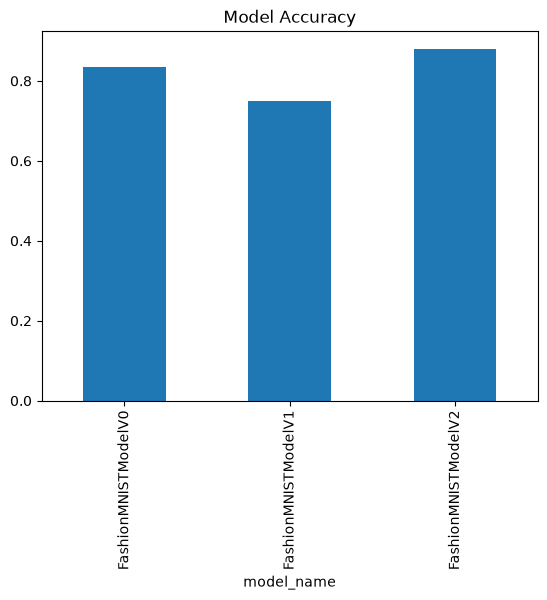

In [61]:
# Visiulizae our data results

compare_results.set_index("model_name")["model_acc"].plot.bar(title="Model Accuracy")

## 9. Make and evaluate random predictions with best model (v2)

In [62]:
def make_predictions(model:nn.Module,
                     data: list,
                     device: torch.device = device):
  pred_probs = []
  model.to(device)
  model.eval()

  with torch.inference_mode():
    for sample in data:
      # Prepare the sample (add a batch dimention and pass it to the targer device)
      sample = torch.unsqueeze(sample, dim=0).to(device)

      # Make a prediction with the model
      pred_logit = model(sample)

      # logits -> prediction problability
      pred_prob = torch.softmax(pred_logit.squeeze(), dim=0)

      # Append the prediction probability to the list
      # Get pred_prob off the GPU for farther computations
      pred_probs.append(pred_prob.cpu())

  # Stack the preb_prob to turn list into a tensor
  return torch.stack(pred_probs)

In [63]:
import random

# random.seed(42)

test_samples = []
test_labels = []

# test_data : what we downloaded from FashionMNIST

for sample, label in random.sample(list(test_data), k=9):
  test_samples.append(sample)
  test_labels.append(label)

# test_samples = test_samples[:10]
# test_lables = test_lables[:1

# View first sample shape
test_samples[0].shape

torch.Size([1, 28, 28])

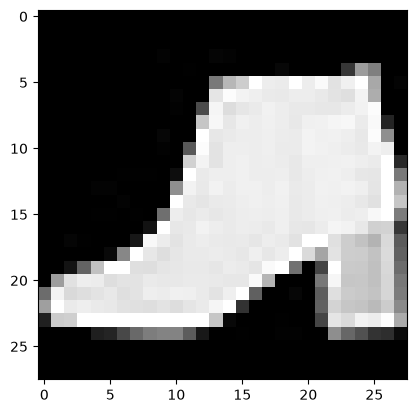

In [64]:
plt.imshow(test_samples[0].squeeze(), cmap="gray")
#

In [65]:
# Make  a prediction

pred_probs = make_predictions(model=model_2,
                              data=test_samples)

# view first 2 prediciotn probabilites
pred_probs[:2]

tensor([[1.1291e-05, 1.3384e-06, 5.2422e-06, 7.0745e-06, 1.6762e-06, 4.6561e-03,
         2.8924e-05, 4.8815e-04, 4.7462e-04, 9.9433e-01],
        [5.4507e-03, 5.4128e-04, 1.1243e-01, 7.2540e-04, 7.7728e-01, 2.7471e-05,
         1.0302e-01, 9.4142e-05, 2.9621e-04, 1.3317e-04]])

In [66]:
# convert prediciotn probabilites -> prediciotn lables

pred_classes = pred_probs.argmax(dim=1)
pred_classes

tensor([9, 4, 4, 7, 8, 1, 5, 3, 4])

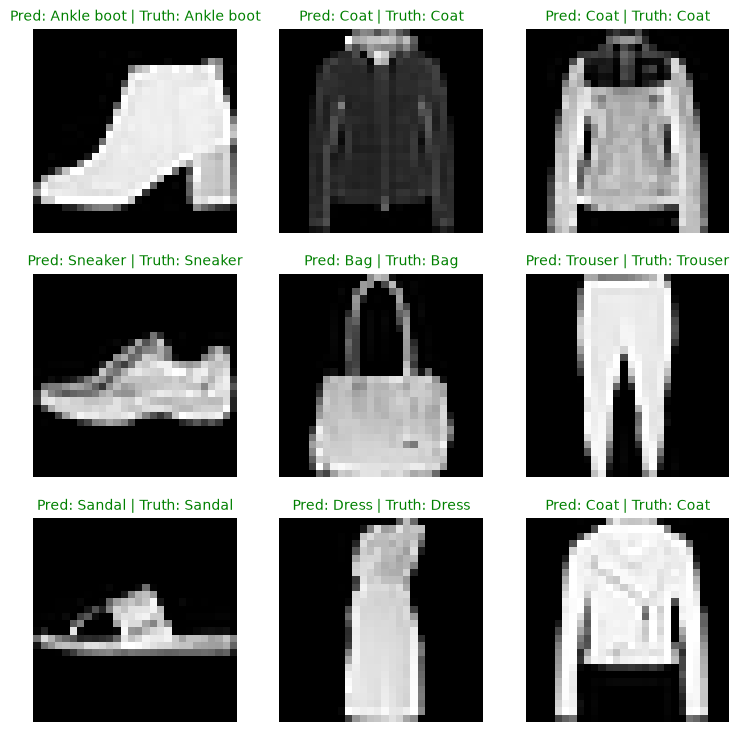

In [67]:

# Plot predictions
plt.figure(figsize=(9, 9))
nrows = 3
ncols = 3
for i, sample in enumerate(test_samples):
  # Create subplot
  plt.subplot(nrows, ncols, i+1)

  # Plot the target image
  plt.imshow(sample.squeeze(), cmap="gray")

  # Find the prediction (in text form, e.g "Sandal")
  pred_label = class_names[pred_classes[i]]

  # Get the truth label (in text form)
  truth_label = class_names[test_labels[i]]

  # Create a title for the plot
  title_text = f"Pred: {pred_label} | Truth: {truth_label}"

  # Check for equality between pred and truth and change color of title text
  if pred_label == truth_label:
    plt.title(title_text, fontsize=10, c="g") # green text if prediction same as truth
  else:
    plt.title(title_text, fontsize=10, c="r")

  plt.axis(False);

### 10. Making a confusion matrix for further prediction evaluation

A confusion matrix is a fantastic way of evaluating your classification models visually: https://www.learnpytorch.io/02_pytorch_classification/#9-more-classification-evaluation-metrics

1. Make predictions with our trained model on the test dataset
2. Make a confusion matrix torchmetrics.ConfusionMatrix - https://torchmetrics.readthedocs.io/en/stable/classification/confusion_matrix.html


3. Plot the confusion matrix using mlxtend.plotting.plot_confusion_matrix() - http://rasbt.github.io/mlxtend/user_guide/plotting/plot_confusion_matrix/

In [68]:
import mlxtend

In [69]:
! pip install tdqm

In [70]:
from tqdm.auto import tqdm

# 1. Make a prediction with the trained model
y_preds=[]
model_2.eval()
with torch.inference_mode():
  for X, y in tqdm(test_dataloader, desc="Making predictions"):
    X, y = X.to(device), y.to(device)
    y_logits = model_2(X)
    y_pred = torch.softmax(y_logits, dim=1).argmax(dim=1)
    y_preds.append(y_pred.cpu())

# Concatenate our predictions list into tensor
print(y_preds)
y_preds = torch.cat(y_preds)
y_preds
#

Making predictions:   0%|          | 0/313 [00:00<?, ?it/s]

[tensor([9, 2, 1, 1, 6, 1, 4, 6, 5, 7, 4, 5, 5, 3, 4, 1, 2, 4, 8, 0, 2, 7, 7, 5,
        1, 2, 6, 0, 9, 3, 8, 8]), tensor([3, 3, 8, 0, 7, 5, 7, 9, 0, 1, 0, 7, 6, 7, 2, 1, 4, 6, 4, 6, 5, 8, 2, 2,
        8, 4, 8, 0, 7, 7, 8, 5]), tensor([1, 1, 4, 3, 7, 8, 7, 0, 2, 6, 2, 3, 1, 2, 8, 4, 1, 8, 5, 9, 5, 0, 3, 2,
        0, 2, 5, 3, 6, 7, 1, 8]), tensor([0, 1, 4, 2, 3, 6, 7, 6, 7, 8, 5, 7, 9, 4, 2, 5, 7, 0, 5, 2, 8, 6, 7, 8,
        0, 0, 9, 9, 3, 0, 8, 4]), tensor([1, 5, 4, 1, 9, 1, 8, 6, 6, 1, 2, 5, 1, 0, 0, 0, 1, 6, 1, 3, 2, 2, 2, 4,
        1, 3, 5, 0, 4, 7, 9, 3]), tensor([7, 2, 3, 9, 0, 9, 4, 7, 4, 2, 0, 5, 4, 1, 2, 1, 3, 0, 9, 1, 0, 9, 3, 6,
        7, 9, 9, 4, 4, 7, 1, 2]), tensor([3, 6, 3, 6, 8, 3, 6, 1, 1, 0, 2, 9, 2, 4, 0, 7, 9, 8, 4, 1, 8, 4, 1, 3,
        1, 6, 7, 2, 8, 5, 6, 0]), tensor([7, 7, 6, 6, 7, 0, 7, 8, 9, 2, 9, 0, 5, 1, 4, 2, 5, 4, 9, 2, 4, 8, 6, 4,
        6, 4, 9, 7, 6, 5, 5, 4]), tensor([8, 5, 2, 3, 0, 4, 8, 0, 0, 6, 3, 8, 9, 6, 1, 3, 0, 2, 3, 0, 8, 3, 7, 4,
       

tensor([9, 2, 1,  ..., 8, 1, 5])

In [71]:

# See if required packages are installed and if not, install them...
try:
  import torchmetrics, mlxtend
  print(f"mlxtend version: {mlxtend.__version__}")
  assert int(mlxtend.__version__.split(".")[1] >= 19, "mlxtend version should be 0.19.0 or higher")
except:
  !pip install torchmetrics -U mlxtend
  import torchmetrics, mlxtend
  print(f"mlxtend version: {mlxtend.__version__}")

mlxtend version: 0.25.0
mlxtend version: 0.25.0


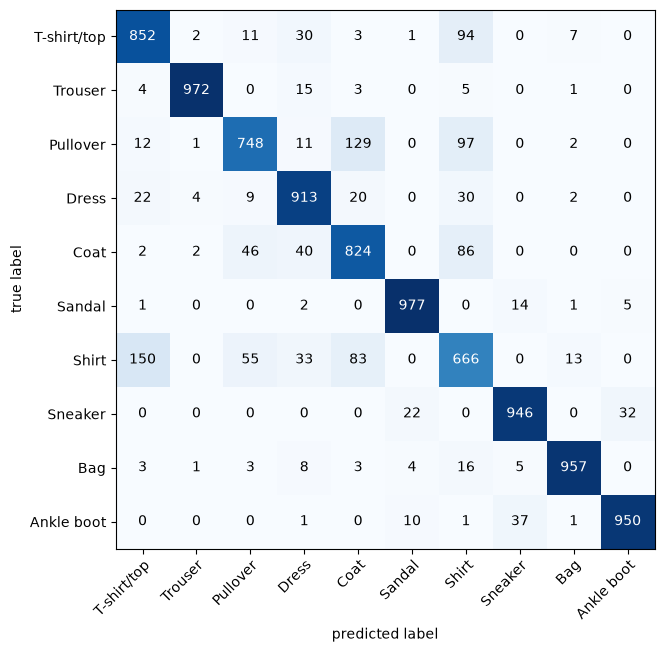

In [75]:
from torchmetrics import ConfusionMatrix
from mlxtend.plotting import plot_confusion_matrix

# 1. setuo confusin matric and compare predictions to target
conf_mat = ConfusionMatrix(task="multiclass", num_classes=len(class_names))
conf_mat_tensor = conf_mat(preds=y_preds, target=test_data.targets) # targets->labels

# conf_mat_tensor

# 3. plot our confucion matrix
fig, ax = plot_confusion_matrix(
    conf_mat=conf_mat_tensor.numpy(), # matplotlib likes working with numpy
    class_names=class_names,
    figsize=(10, 7)
)

### 11. Saving and loading best performing model



In [76]:
from pathlib import Path

# Create model dictory path
MODEL_PATH = Path("models")
MODEL_PATH.mkdir(parents=True,
                 exist_ok=True)

# Create model save
MODEL_NAME = "03_pytorch_computer_vision_model_2.pth"
MODEL_SAVE_PATH = MODEL_PATH / MODEL_NAME

MODEL_SAVE_PATH

PosixPath('models/03_pytorch_computer_vision_model_2.pth')

In [77]:
# Save the model state dict
print(f"Saving model to: {MODEL_SAVE_PATH}")
torch.save(obj=model_2.state_dict(),
           f=MODEL_SAVE_PATH)

Saving model to: models/03_pytorch_computer_vision_model_2.pth


In [78]:
 # Create a new instance

torch.manual_seed(RANDOM_SEED)

loaded_model_2 = FashionMNISTModelV2(input_shape=1,
                                     hidden_units=10,
                                     output_shape=len(class_names))

loaded_model_2.load_state_dict(torch.load(MODEL_SAVE_PATH))

<All keys matched successfully>

In [79]:
loaded_model_2.to(device)

FashionMNISTModelV2(
  (conv_block_1): Sequential(
    (0): Conv2d(1, 10, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (1): ReLU()
    (2): Conv2d(10, 10, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (3): ReLU()
    (4): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  )
  (conv_block_2): Sequential(
    (0): Conv2d(10, 10, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (1): ReLU()
    (2): Conv2d(10, 10, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (3): ReLU()
    (4): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  )
  (classifier): Sequential(
    (0): Flatten(start_dim=1, end_dim=-1)
    (1): Linear(in_features=490, out_features=10, bias=True)
  )
)

In [80]:
# Evaluate our model
model_2_results

{'model_name': 'FashionMNISTModelV2',
 'model_loss': 0.32718968391418457,
 'model_acc': 0.88069087266922}

In [83]:
torch.manual_seed(RANDOM_SEED)

loaded_model_2_results = eval_model(model=loaded_model_2,
                                    data_loader=test_dataloader,
                                    accuracy_fn=accuracy_fn,
                                    device=device,
                                    loss_fn=loss_fn)
loaded_model_2_results

{'model_name': 'FashionMNISTModelV2',
 'model_loss': 0.32718968391418457,
 'model_acc': 0.88069087266922}

In [85]:
# chech if the models resutls are close to each other
torch.isclose(torch.tensor(model_2_results["model_loss"]),
              torch.tensor(loaded_model_2_results["model_loss"]),
              atol=1e-02)

tensor(True)